# Experiments

In [1]:

# add scripts folder to path
import sys
# sys.path.insert(0, r'C:\Users\wesle\Desktop\repository\music-code-master\scripts')
# sys.path.insert(0, r'.\Script\CodeToMusic\Music-Code\core')
sys.path.insert(0, r'E:\WORK\PROJECT\git\PersonalAssistant\Script\CodeToMusic\Music-Code\core')


# import library
from music_code import MusicCode

# initialize
m = MusicCode(120)




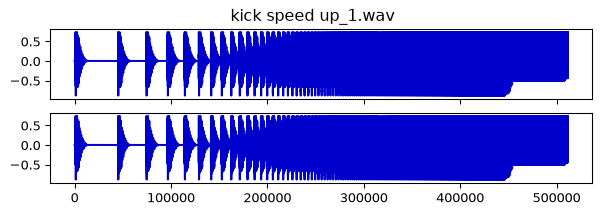

In [4]:
# KICK SPEED UP

# empty container for wave
speed_up = m.rest(1/100)

# create speed up pattern by gradually decreasing time_edit duration and joining waves

total_kicks = 500

for i in range(2,total_kicks):
    kick = m.sample('kick',1).time_edit(1/i)
    speed_up = m.join_waves((speed_up, kick))
    
speed_up.bounce('kick speed up.wav')

# Bass

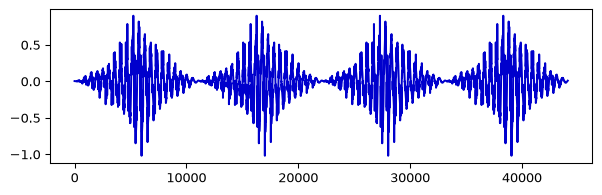

In [5]:
# rhythm
rate = 1/8

# ADSR
attack = 1/16
release = 1/8

# create many layers with identical rhythm, duration and ADSR settings
E_sine = m.sequence(['E1'], 'sine', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(3)

# adjust wt_pos with sine wave to create cool harmonics
E_sine_2 = m.sequence(['E3'], 'sine', rhythm=rate, duration=1/2, wt_pos=9999, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(2)
E_sine_3 = m.sequence(['B3'], 'sine', rhythm=rate, duration=1/2, wt_pos=77777, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.9)

# fill frequency spectrum
E_tri = m.sequence(['E1'], 'tri', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(1.5)
E_saw1 = m.sequence(['E2'], 'saw1', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.4)
E_square1 = m.sequence(['E1'], 'square', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.3)
E_square2 = m.sequence(['E2'], 'square', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.4)

# LPF and HPF, keep sub and upper seperate
bass_sub = E_sine.LPF(100)
bass_upper = m.add_waves((E_tri, E_saw1, E_square1, E_square2, E_sine_2, E_sine_3)).HPF(100)

# join waves and push volume beyond 1 for clipping/distortion
bass1 = m.add_waves((bass_sub,bass_upper)).vol(2)

# WAV audio
bass1.bounce()

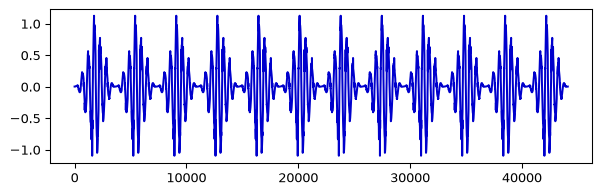

In [6]:
# rhythm
rate = 1/24

# ADSR
attack = 1/48
release = 1/24

# create many layers with identical rhythm, duration and ADSR settings
E_sine = m.sequence(['E1'], 'sine', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(3)

# adjust wt_pos with sine wave to create cool harmonics
E_sine_2 = m.sequence(['E3'], 'sine', rhythm=rate, duration=1/2, wt_pos=99999, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(2)
E_sine_3 = m.sequence(['B3'], 'sine', rhythm=rate, duration=1/2, wt_pos=77777, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.9)

# fill frequency spectrum
E_tri = m.sequence(['E1'], 'tri', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(1.5)
E_saw1 = m.sequence(['E2'], 'saw1', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.4)
E_square1 = m.sequence(['E1'], 'square', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.3)
E_square2 = m.sequence(['E2'], 'square', rhythm=rate, duration=1/2, fade_in=attack, in_curve=4, fade_out=release, out_curve=3).vol(.4)

# add all layers into one waveform
bass2 = m.add_waves((E_sine, E_tri, E_saw1, E_square1, E_square2, E_sine_2, E_sine_3)).vol(2)

# WAV audio
bass2.bounce()

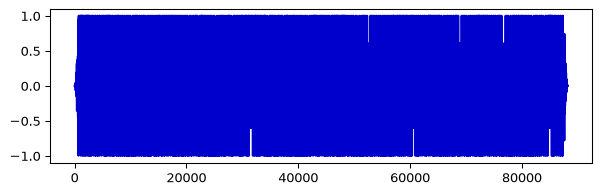

In [7]:
m.chord("lydian chord", "B3", 'square', 1).bounce()

# Automated Dataset Generator

In [9]:
two_octaves = list(m.freq_note_table_sharp.values())[24:48]
chord_qualities = ['maj triad', 'min triad', 'maj 7', 'min 7', 'lydian chord', 'maj 6 9']

In [12]:
# for note in two_octaves:
#     for quality in chord_qualities:
#         for waveform_type in ['sine','tri','saw1','square']:
        
#             waveform = m.chord(quality, note, waveform_type, 1)

#             file_name = str(note + "_" + quality + "_" + waveform_type + "_" +"chords set.wav")

#             waveform.bounce(file_name, show_visual=False)
from pathlib import Path

# Define your specific custom directory
output_dir = Path(r"E:\WORK\PROJECT\git\PersonalAssistant\Script\CodeToMusic\Music-Code\notebooks\tutorials\output_chords")

# Create the directory (and any parent folders) if it doesn't exist
output_dir.mkdir(parents=True, exist_ok=True)

for note in two_octaves:
    for quality in chord_qualities:
        for waveform_type in ['sine', 'tri', 'saw1', 'square']:
            
            waveform = m.chord(quality, note, waveform_type, 1)
            
            # Combine the custom directory with the filename as a string
            file_name = output_dir / f"{note}_{quality}_{waveform_type}_chords set.wav"
            
            # Passing an absolute path string bypasses the default framework export folder
            waveform.bounce(str(file_name), show_visual=False)

print(f"All audio files generated successfully inside: {output_dir}")

All audio files generated successfully inside: E:\WORK\PROJECT\git\PersonalAssistant\Script\CodeToMusic\Music-Code\notebooks\tutorials\output_chords
